# 14 Anomaly features, 09:00 cutoff

Notebook 13 suggested that absolute demand, wind and solar forecasts carry seasonal information the reference already contains, so in recent folds the learned deviation from the reference is too negative. Notebook 05 now has anomaly features (forecast minus its own D-29..D-2 same-clock-time mean at the same cutoff). Four variants, fixed before running and all reported, each for Huber regression (alpha 30) and gradient boosting, predicting the deviation from the 28-day median (`ref28`):

| Variant | Weather inputs | Level terms (`history`) |
| --- | --- | --- |
| V0 | absolute only (as in 12) | yes |
| V1 | absolute + anomaly | yes |
| V2 | anomaly only | yes |
| V3 | anomaly only | no |

Margin, seasonal and calendar terms are the same in all four. Same 17 folds; results over all folds, folds 0-12 and the last four (13-16). The decision rule is set in advance: a variant is only of interest if it improves the late folds without losing the earlier ones.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
VAL = D9["day"].isin(val_days_all)
REF = "med28_same"
COMMON = D9[REF].notna() & D9["price"].notna()
late_days = pd.DatetimeIndex(np.concatenate([folds[k]["val_days"].values for k in range(13, 17)]))
LATE = D9["day"].isin(late_days) & COMMON
print(len(D9), "rows;", int((VAL & COMMON).sum()), "scored;", [c for c in D9.columns if c.endswith("_anom")])

32351 rows; 22845 scored; ['demand_anom', 'wind_anom', 'emb_wind_anom', 'emb_solar_anom', 'wind_total_anom']


## 1. Variants

In [2]:
ABS = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
ANOM = ["demand_anom", "wind_anom", "emb_wind_anom", "emb_solar_anom"]
HIST = ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"]
MGN = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
OTH = ["bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
# gradient boosting also gets the extra forecast columns it used in 07 (wind total, ages, revisions)
GBM_EXTRA = ["wind_total_mw", "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev", "is_weekend"]

VARIANTS = {
    "V0 absolute + history":        dict(weather=ABS,        hist=True),
    "V1 absolute+anomaly + history": dict(weather=ABS + ANOM, hist=True),
    "V2 anomaly + history":         dict(weather=ANOM,       hist=True),
    "V3 anomaly, no history":       dict(weather=ANOM,       hist=False),
}

def linear_model(weather, hist):
    lin = (HIST if hist else []) + MGN + OTH
    pre = ColumnTransformer([
        ("spl", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(n_knots=6, degree=3, extrapolation="linear"), StandardScaler()), weather),
        ("hour", SplineTransformer(knots=np.linspace(0, 24, 13).reshape(-1, 1), degree=3, extrapolation="periodic"), ["hour_frac"]),
        ("lin", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), lin),
        ("wd", OneHotEncoder(handle_unknown="ignore"), ["weekday"])])
    cols = weather + ["hour_frac"] + lin + ["weekday"]
    return Pipeline([("pre", pre), ("est", HuberRegressor(alpha=30, epsilon=1.35, max_iter=300))]), cols

def gbm_model(weather, hist):
    cols = ["hour_frac", "weekday", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"] + weather + MGN + GBM_EXTRA
    if weather != ANOM:
        pass
    if hist:
        cols += HIST
    if set(weather) == set(ANOM) or set(weather) == set(ABS + ANOM):
        pass
    if set(weather) == set(ANOM):            # anomaly only: drop the absolute weather columns that GBM_EXTRA would re-add
        cols = [c for c in cols if c not in ("wind_total_mw",)]
    m = HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                      min_samples_leaf=100, l2_regularization=1.0, early_stopping=False, random_state=0)
    return m, list(dict.fromkeys(cols))

def run_cv(kind, spec):
    pred = pd.Series(np.nan, index=D9.index); dev = pred.copy()
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & COMMON]
        va = D9[D9["day"].isin(f["val_days"])]
        m, cols = (linear_model if kind == "huber" else gbm_model)(spec["weather"], spec["hist"])
        m.fit(tr[cols], tr["price"] - tr[REF])
        dev.loc[va.index] = m.predict(va[cols]); pred.loc[va.index] = dev.loc[va.index] + va[REF]
    return pred, dev

def fold_table(pred):
    rows = []
    for f in folds:
        d = D9[D9["day"].isin(f["val_days"]) & COMMON].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = fold_table(D9[REF])
for k, v in VARIANTS.items():
    print(k, "| huber inputs:", len(linear_model(v["weather"], v["hist"])[1]), "| gbm inputs:", len(gbm_model(v["weather"], v["hist"])[1]))

V0 absolute + history | huber inputs: 22 | gbm inputs: 31
V1 absolute+anomaly + history | huber inputs: 26 | gbm inputs: 35
V2 anomaly + history | huber inputs: 22 | gbm inputs: 30
V3 anomaly, no history | huber inputs: 15 | gbm inputs: 23


## 2. Run

`dMAE` etc. are mean per-fold differences to the 28-day median baseline (negative is better for MAE and RMSE; positive for hit rates). `pred dev late` and `actual dev late` are the mean predicted and actual deviation from `ref28` over folds 13-16.

In [3]:
RES, FT, PRED = {}, {}, {}
t0 = time.time()
for kind in ["huber", "gbm"]:
    for vname, spec in VARIANTS.items():
        key = f"{kind} {vname}"
        pred, dev = run_cv(kind, spec)
        PRED[key] = pred; ft = fold_table(pred); FT[key] = ft
        d = {m: ft[m] - BASE[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
        RES[key] = {"dMAE all": d["MAE"].mean(), "dMAE 0-12": d["MAE"].loc[:12].mean(), "dMAE late": d["MAE"].loc[13:].mean(),
                    "dRMSE all": d["RMSE"].mean(), "dRMSE late": d["RMSE"].loc[13:].mean(),
                    "dHitTop all": d["hit_top8"].mean(), "dHitTop late": d["hit_top8"].loc[13:].mean(),
                    "dHitBot all": d["hit_bot8"].mean(), "dHitBot late": d["hit_bot8"].loc[13:].mean(),
                    "bias late": ft["bias"].loc[13:].mean(), "bias f16": ft["bias"].loc[16],
                    "pred dev late": dev[LATE].mean(), "actual dev late": (D9["price"] - D9[REF])[LATE].mean()}
        print(f"{key:36s} {time.time() - t0:4.0f}s")
R = pd.DataFrame(RES).T
print(R.round(2).to_string())
P = pd.DataFrame(PRED)
for c in ["day", "period_start", "price", REF]:
    P[c] = D9[c]
P.loc[VAL].to_parquet("outputs/cv_preds_anomaly_0900.parquet", index=False)

huber V0 absolute + history             8s


huber V1 absolute+anomaly + history    20s


huber V2 anomaly + history             27s


huber V3 anomaly, no history           33s


gbm V0 absolute + history              48s


gbm V1 absolute+anomaly + history      66s


gbm V2 anomaly + history               82s


gbm V3 anomaly, no history             96s
                                     dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop all  dHitTop late  dHitBot all  dHitBot late  bias late  bias f16  pred dev late  actual dev late
huber V0 absolute + history             -1.90      -2.41      -0.24      -4.12       -1.82         0.03          0.01         0.05          0.00     -11.77    -15.36         -11.09             0.68
huber V1 absolute+anomaly + history     -1.81      -2.24      -0.40      -3.91       -1.99         0.03          0.01         0.03         -0.00     -10.78    -14.45         -10.10             0.68
huber V2 anomaly + history              -1.88      -2.26      -0.63      -3.92       -2.06         0.01          0.00         0.02         -0.01      -6.46    -11.55          -5.78             0.68
huber V3 anomaly, no history            -1.80      -1.96      -1.29      -3.69       -2.89         0.01          0.00         0.03         -0.00      -2.42     -7.61

## 3. Variants against V0, paired by fold

Difference between each variant and V0 of the same model family (mean over folds +/- standard error over the 17 folds), for all folds and for folds 13-16. This shows whether the anomaly variants change anything relative to the model used so far.

In [4]:
rows = {}
for kind in ["huber", "gbm"]:
    v0 = FT[f"{kind} V0 absolute + history"]
    for vname in list(VARIANTS)[1:]:
        ft = FT[f"{kind} {vname}"]
        r = {}
        for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
            d = ft[m] - v0[m]
            r[f"{m} all"] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(17):.3f}"
            r[f"{m} late"] = f"{d.loc[13:].mean():+.3f}"
        rows[f"{kind} {vname}"] = r
print(pd.DataFrame(rows).T.to_string())

                                              MAE all MAE late          RMSE all RMSE late      hit_top8 all hit_top8 late      hit_bot8 all hit_bot8 late
huber V1 absolute+anomaly + history  +0.094 +/- 0.180   -0.169  +0.207 +/- 0.215    -0.169  -0.004 +/- 0.003        +0.004  -0.015 +/- 0.007        -0.009
huber V2 anomaly + history           +0.023 +/- 0.193   -0.396  +0.204 +/- 0.282    -0.242  -0.024 +/- 0.006        -0.006  -0.024 +/- 0.012        -0.018
huber V3 anomaly, no history         +0.098 +/- 0.327   -1.055  +0.429 +/- 0.422    -1.067  -0.025 +/- 0.006        -0.007  -0.021 +/- 0.011        -0.006
gbm V1 absolute+anomaly + history    -0.238 +/- 0.238   -0.070  -0.434 +/- 0.337    -0.699  +0.001 +/- 0.004        +0.003  +0.000 +/- 0.013        -0.008
gbm V2 anomaly + history             -0.268 +/- 0.287   -0.285  -0.439 +/- 0.449    -0.922  -0.012 +/- 0.005        -0.003  -0.015 +/- 0.012        -0.012
gbm V3 anomaly, no history           -0.176 +/- 0.386   -1.020  -0.244

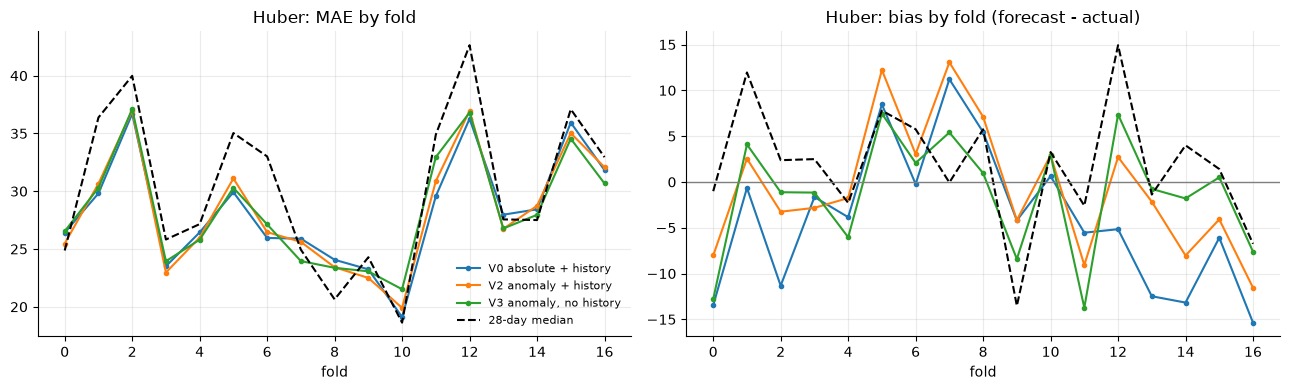

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key in ["huber V0 absolute + history", "huber V2 anomaly + history", "huber V3 anomaly, no history"]:
    axes[0].plot(FT[key]["MAE"], marker="o", ms=3, label=key.replace("huber ", ""))
    axes[1].plot(FT[key]["bias"], marker="o", ms=3, label=key.replace("huber ", ""))
axes[0].plot(BASE["MAE"], "k--", label="28-day median"); axes[1].plot(BASE["bias"], "k--", label="28-day median")
axes[0].set_title("Huber: MAE by fold"); axes[1].set_title("Huber: bias by fold (forecast - actual)")
axes[1].axhline(0, color="grey", lw=1); axes[0].legend(frameon=False, fontsize=8)
for ax in axes: ax.set_xlabel("fold")
plt.tight_layout(); plt.show()

## Findings (09:00, 17 folds; four pre-specified variants x two model families; differences to the 28-day median baseline)

- **Anomaly features reduce the late-fold under-forecast, and removing the level terms as well removes most of it.** Huber, folds 13-16, mean error: V0 -11.8, V1 -10.8, V2 -6.5, V3 -2.4 (actual deviation from `ref28` is +0.7, predicted deviation -11.1, -10.1, -5.8, -1.7). GBM: -14.5, -12.8, -9.1, -4.3. So the mechanism proposed in notebook 13 is supported: both the absolute weather levels and the level terms push the forecast down in the recent regime, and each removal helps.
- **The late-fold accuracy improves.** V3 against the baseline in folds 13-16: MAE -1.29 (Huber) and -1.17 (GBM), against -0.24 and -0.15 for V0; RMSE -2.9 and -3.0, against -1.8 and -1.2. Fold 16 mean error improves from -15.4 to -7.6 (Huber) and from -18.9 to -12.2 (GBM). This is on four folds only.
- **The all-fold MAE gain is mostly kept, the early gain is partly lost.** V3 all folds: MAE -1.80 (Huber) and -1.69 (GBM), against -1.90 and -1.51 for V0; over folds 0-12 -1.96 and -1.85 against -2.41 and -1.93. Paired against V0 over all 17 folds the MAE difference is +0.10 +/- 0.33 (Huber) and -0.18 +/- 0.39 (GBM), i.e. not distinguishable from zero.
- **The ranking gain is lost.** The within-day hit-rate gains over the baseline drop from +0.03/+0.05 (Huber V0) to +0.01/+0.03 (V3), and against V0 over all folds V3 is -0.025 +/- 0.006 (top-8) and -0.021 +/- 0.011 (bottom-8) for Huber, and -0.013 +/- 0.004 and -0.020 +/- 0.012 for GBM. A plausible reason (not tested): within a day, which hours are expensive depends on the absolute demand and wind in those hours, and an anomaly (forecast minus its typical value at that clock time) removes that intraday information. In the late folds the hit-rate gains were already about zero for V0, so nothing is lost there.
- **V1 (absolute + anomaly) is no better than V0** for Huber (MAE +0.09 +/- 0.18) and slightly better for GBM (-0.24 +/- 0.24, not significant); its late bias is only a little smaller.
- **Reading against the decision rule set beforehand** (a variant is of interest only if it improves the late folds without losing the earlier ones): V3 improves the late folds clearly and keeps the MAE and RMSE gains over all folds, but gives up the ranking gain, which is the headline metric in D-004. So the result is a trade-off between ranking skill in earlier regimes and level accuracy in the recent one, not a clean win. Which to prefer depends on how much weight the hold-out (the highest-price regime) and the ranking metric each get.
- **What would address the trade-off (not yet tried):** anomalies for the level together with the absolute hour-level shape (V1 does this but kept the level terms); a two-part model (ranking from absolute features, level from anomaly features); or weighting recent days. The choice should not be made from these folds alone.
